Week 2 — Exploratory Data Analysis: NextGenLearners Applicant Insights- by Mwelwa Kashingwa

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.dates as mdates
import plotly.express as px

df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])

In [3]:
# Have an idea of the contents of the file by checking it
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    78 non-null     object        
 1   Email             78 non-null     object        
 2   Phone             78 non-null     int64         
 3   Domain Applied    78 non-null     object        
 4   University        78 non-null     object        
 5   Application Date  76 non-null     datetime64[ns]
 6   Status            78 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 4.4+ KB


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Farah Siddiqui,farah.siddiqui46@outlook.com,3210471235,Web Development,IBA,2026-04-11,Under Review
1,Usman Ahmed,usman.ahmed@hotmail.com,3122863352,Data Science,University of the Punjab,2026-04-16,Under Review
2,Areeba Zaidi,areeba.zaidi69@hotmail.com,3467099740,Cybersecurity,IBA Karachi,2026-04-30,Selected
3,Ayesha Zaidi,ayesha.zaidi@hotmail.com,3358083375,Data Science,IBA Karachi,2026-04-06,Under Review
4,Daniyal Javed,daniyal.javed@outlook.com,3452651916,Cybersecurity,IBA Karachi,2026-04-08,Rejected


In [4]:
# Which Domain Received the Most Applications?
domain_counts = df['Domain Applied'].value_counts()
print(domain_counts)

Domain Applied
Cybersecurity             21
UI/UX Design              18
Web Development           16
Data Science              14
Mobile App Development     9
Name: count, dtype: int64


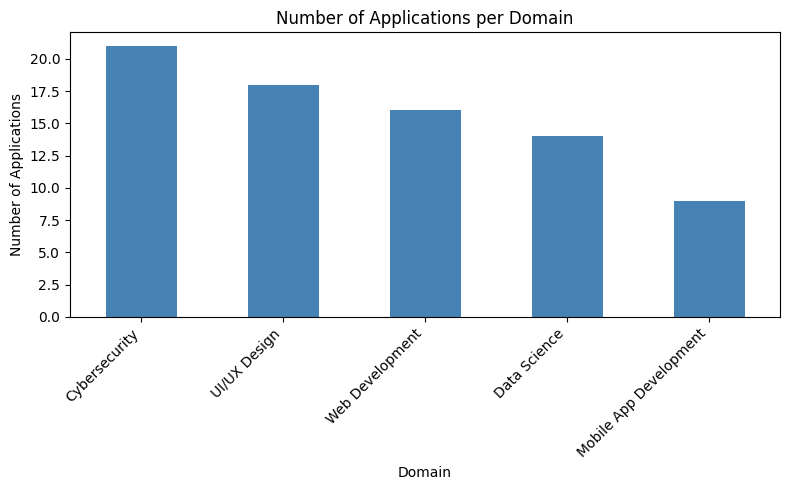

In [5]:
# Which Domain Received the Most Applications?- Visualization bar chart
plt.figure(figsize=(8,5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Cybersecurity recieveid the highest number of applicants (21), more than double the lowest domain, Mobile App Development (9)

In [6]:
# How Did Applications Trend Over Time?
# Group by month
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()
print(monthly_trend)

Application Month
2026-02     1
2026-03     1
2026-04    40
2026-05    32
2026-11     2
Freq: M, dtype: int64


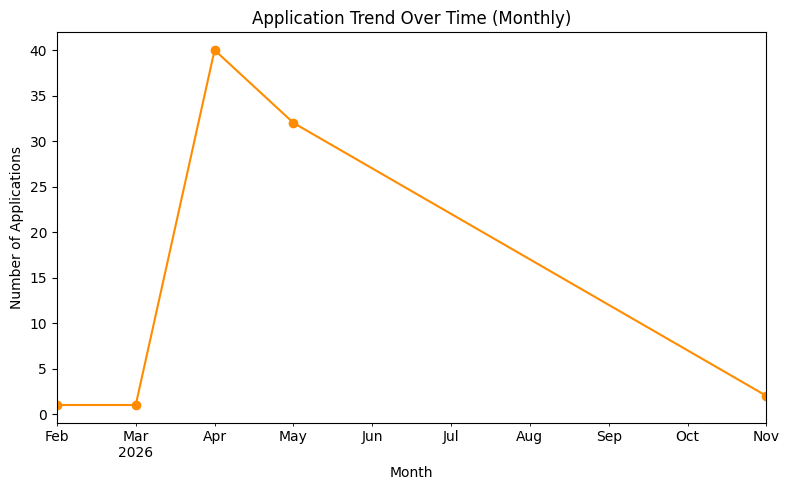

In [7]:
# Application trend over time visualization chart
# Why a line chart here, not a bar chart? Line charts are the standard choice for showing change over a continuous timeline — they make trends (increasing, decreasing, spikes)
# visually obvious in a way bar charts don't as clearly.

plt.figure(figsize=(8,5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()

Applications spiked in April 2026, likely correlating with the internship program announcement, then gradually declined toward the application deadline.

In [8]:
# What's the Acceptance Rate — Overall
status_counts = df['Status'].value_counts()
print(status_counts)

Status
Selected        29
Under Review    28
Rejected        21
Name: count, dtype: int64


In [9]:
# Acceptance rate per-domain breakdown using pivot_table():
status_by_domain = pd.pivot_table(
df,
index='Domain Applied',
columns='Status',
values='Applicant Name',
aggfunc='count',
fill_value=0
)
print(status_by_domain)

Status                  Rejected  Selected  Under Review
Domain Applied                                          
Cybersecurity                  4        10             7
Data Science                   5         3             6
Mobile App Development         2         2             5
UI/UX Design                   4         8             6
Web Development                6         6             4


In [10]:
# Acceptance rate per-domain in percentages because percentages let you compare fairly across domains with different application volumes.
# Percentages show the proportion of applicants selected, allowing you to compare success rates fairly regardless of how many applications each domain received.
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
print(status_by_domain_pct.round(1))

Status                  Rejected  Selected  Under Review
Domain Applied                                          
Cybersecurity               19.0      47.6          33.3
Data Science                35.7      21.4          42.9
Mobile App Development      22.2      22.2          55.6
UI/UX Design                22.2      44.4          33.3
Web Development             37.5      37.5          25.0


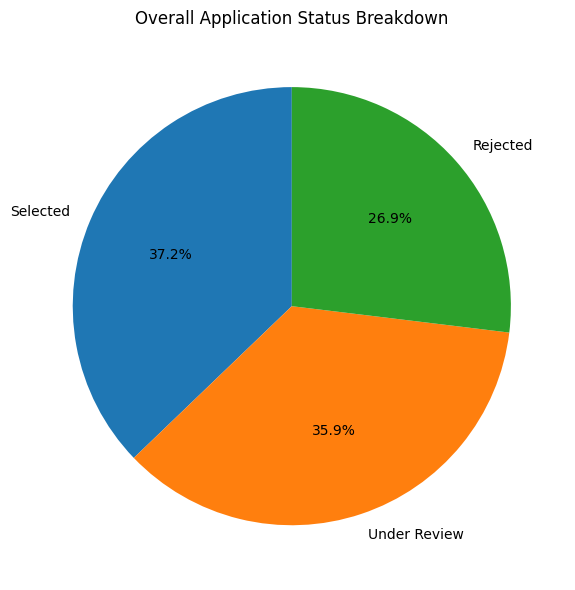

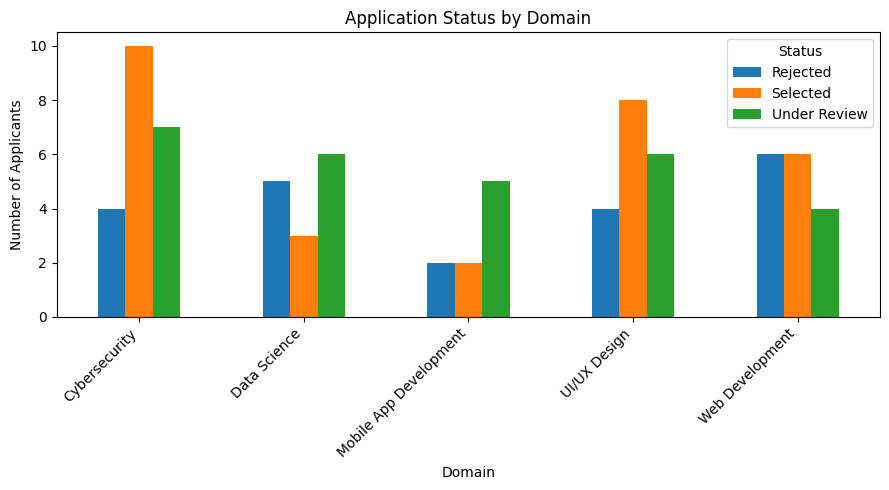

In [11]:
# The visualization (a pie chart for overall status, and a stacked/grouped bar chart for per-domain):

# Overall status - pie chart
plt.figure(figsize=(6,6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Overall Application Status Breakdown')
plt.ylabel('') # removes the default awkward y-label pie charts add
plt.tight_layout()
plt.show()

# Per-domain - grouped bar chart
status_by_domain.plot(kind='bar', figsize=(9,5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

In [12]:
# Which Universities Sent the Most Applicants?
top_universities = df['University'].value_counts().head(10)
print(top_universities)
df.head(10)

University
University of the Punjab    12
IBA Karachi                 12
NUST                         9
LUMS                         6
FAST-NUCES                   6
GIKI                         6
COMSATS University           5
Not Specified                4
UET Lahore                   3
IBA                          2
Name: count, dtype: int64


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,Application Month
0,Farah Siddiqui,farah.siddiqui46@outlook.com,3210471235,Web Development,IBA,2026-04-11,Under Review,2026-04
1,Usman Ahmed,usman.ahmed@hotmail.com,3122863352,Data Science,University of the Punjab,2026-04-16,Under Review,2026-04
2,Areeba Zaidi,areeba.zaidi69@hotmail.com,3467099740,Cybersecurity,IBA Karachi,2026-04-30,Selected,2026-04
3,Ayesha Zaidi,ayesha.zaidi@hotmail.com,3358083375,Data Science,IBA Karachi,2026-04-06,Under Review,2026-04
4,Daniyal Javed,daniyal.javed@outlook.com,3452651916,Cybersecurity,IBA Karachi,2026-04-08,Rejected,2026-04
5,Sidra Mirza,sidra.mirza@hotmail.com,3019175517,Cybersecurity,Not Specified,2026-04-10,Rejected,2026-04
6,Anum Zaidi,anum.zaidi2@hotmail.com,3337720943,Cybersecurity,UET Lahore,2026-05-27,Selected,2026-05
7,Laiba Butt,laiba.butt@gmail.com,3099389314,Cybersecurity,University of the Punjab,2026-04-15,Selected,2026-04
8,Noor Iqbal,noor.iqbal@gmail.com,3449398492,Cybersecurity,NUST,2026-04-21,Selected,2026-04
9,Faisal Ahmed,faisal.ahmed@gmail.com,3174978773,Web Development,LUMS,2026-03-04,Under Review,2026-03


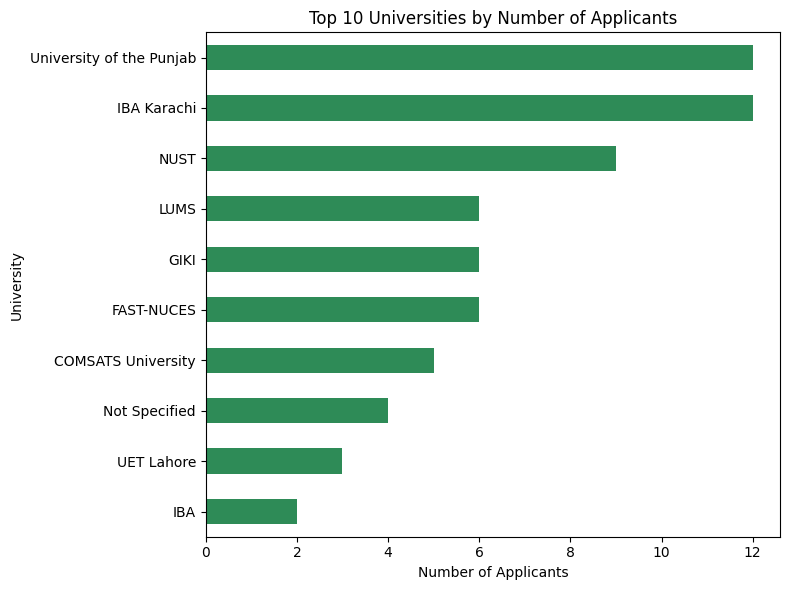

In [13]:
# Most university application - horizontal bar chart
plt.figure(figsize=(8,6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

**Bonus Question: Average time between application date and today (if relevant) to see how "fresh" applications are**

I chose this question because it required more than simply extracting data. I had to calculate the duration between each application date and today's date, as this information was not provided in the dataset. Unlike the other questions, which relied on concepts covered in the previous week's material, this question encouraged me to conduct additional research and apply my knowledge to a new problem. The first two questions also covered concepts explained in the work PDF, so I wanted to challenge myself with a question that required greater independent exploration.

In [15]:
# Bonus chart - Average time between application date and today (if relevant) to see how "fresh" applications are

df = df.dropna(subset=['Application Date']).copy()

# Ensure Application Date is in datetime format
df['Application Date'] = pd.to_datetime(df['Application Date'])

# Calculate duration in days
today = pd.Timestamp.today().normalize()
df['Duration_Days'] = (today - df['Application Date'].dt.normalize()).dt.days

# Sort chronologically
df_sorted = df.sort_values('Application Date')

# Create interactive line graph
fig = px.line(
    df_sorted,
    x='Application Date',
    y='Duration_Days',
    markers=True,
    title='Timeline: Application Date vs. Current Date',
    labels={
        'Application Date': 'Application Date',
        'Duration_Days': 'Duration Up to Today (Days)'
    },
    hover_data={
        'Application Date': '|%d %B %Y',
        'Duration_Days': True
    }
)

# Customize appearance
fig.update_traces(
    line=dict(color='#1f77b4', width=2),
    marker=dict(size=7),
    hovertemplate=(
        'Application Date: %{x|%d %B %Y}<br>'
        'Duration: %{y} days'
        '<extra></extra>'
    )
)

fig.update_layout(
    width=1000,
    height=600,
    yaxis=dict(
        range=[140, 240],
        tickmode='linear',
        tick0=140,
        dtick=10,
        title='Duration Up to Today (Days)'
    ),
    xaxis=dict(
        tickformat='%B',
        dtick='M1',
        tickangle=45,
        title='Application Date 2026'
    ),
    hovermode='closest'
)

fig.show()


**Key Insights**
- Cybersecurity is the most popular domain by far, receiving nearly
2x more applications than the least popular domain, Mobile App Development.
- Applications peaked in April 2026 and declined steadily afterwards,
suggesting outreach/marketing efforts were most effective earlier
in the recruitment window.
- Cybersecurity has the highest application volume (47.6%). Even though Mobile App Development received the lowest number of applicants, it has a higher acceptance rate (22.2%) compared to Data Science (21.4%)
suggesting less competition.
- Applicants are concentrated in a small number of universities —the top 3 universities account for nearly 43.3% of all applications, which could guide where future outreach efforts are focused.

**Key / Graph Interpretation**
- **Early March:** One application was submitted much earlier than the others.
- **April to early May:** Many applications were submitted during this period.
- **Early to mid-May:** Fewer applications were submitted during this period.
- **Mid-May to June:** Applications increased again, with many submitted during this period.